# Structural Balance in the Bitcoin Alpha Trust Network

**Course project in Social Network Analysis**  
**Syllabus alignment:** positive and negative relationships, structural balance, graph theory, and network data.

This notebook asks whether positive and negative trust ties form balanced triads more often than expected when the same network topology and overall sign counts are retained but signs are randomly reassigned.

**Main finding:** 85.64% of 21,677 closed triads are balanced in the undirected signed projection. Across 1,000 sign permutations, the mean is 76.94%, and none reaches the observed value. This is evidence of sign organization relative to the stated null model, not a causal claim.

## 1. Data and network model

The SNAP file records `source, target, rating, time`. The source user rates the target on a scale from -10 (distrust) to +10 (trust). For structural balance, this project needs an undirected signed graph. It groups records by unordered user pair and averages reciprocal ratings. A positive mean produces a positive tie, a negative mean produces a negative tie, and an exact zero is marked neutral and omitted. This projection is stated explicitly because reciprocal trust can be asymmetric.

In [1]:
from pathlib import Path
import json
import sys
import pandas as pd
from IPython.display import Image, display

ROOT = next(p for p in (Path.cwd(), *Path.cwd().parents) if (p / "src" / "analyze.py").exists())
sys.path.insert(0, str(ROOT / "src"))
import analyze

raw, aggregated_pairs, G = analyze.load_data()
print(f"Raw ratings: {len(raw):,}")
print(f"Distinct users: {G.number_of_nodes():,}")
print(f"Unordered pairs before neutral removal: {len(aggregated_pairs):,}")
print(f"Neutral pairs removed: {(aggregated_pairs['sign'] == 0).sum():,}")
print(f"Signed graph ties: {G.number_of_edges():,}")
display(raw.head())

source,target,rating,time,u,v
7188,1,10,1407470400,1,7188
430,1,10,1376539200,1,430
3134,1,10,1369713600,1,3134
3026,1,10,1350014400,1,3026
3010,1,10,1347854400,1,3010


Raw ratings: 24,186
Distinct users: 3,783
Unordered pairs before neutral removal: 14,124
Neutral pairs removed: 43
Signed graph ties: 14,081


## 2. Structural balance rule

For a closed triad, multiply the three edge signs. A positive product means the triad is balanced. Thus three positive ties are balanced, and a triad with one positive tie and two negative ties is also balanced. A negative product means the triad is unbalanced. The test includes every triangle in the projected graph.

In [2]:
triangle_triples, edge_pairs = analyze.triangle_edge_indices(G)
import numpy as np
edge_signs = np.asarray([G[u][v]["sign"] for u, v in edge_pairs], dtype=np.int8)
triangle_edges = np.asarray(triangle_triples, dtype=np.int32)
triangle_products = np.prod(edge_signs[triangle_edges], axis=1)
observed_fraction = float(np.mean(triangle_products > 0))
print(f"Closed triads: {len(triangle_edges):,}")
print(f"Balanced triads: {int(np.sum(triangle_products > 0)):,} ({observed_fraction:.2%})")
print(f"Unbalanced triads: {int(np.sum(triangle_products < 0)):,} ({np.mean(triangle_products < 0):.2%})")

Closed triads: 21,677
Balanced triads: 18,565 (85.64%)
Unbalanced triads: 3,112 (14.36%)


## 3. Sign-shuffle null model

The null model holds the undirected graph fixed and randomly shuffles its observed edge signs. Each permutation therefore preserves the topology and the total numbers of positive and negative ties. It does not preserve each user's own balance of positive and negative ties. We use 1,000 permutations with a fixed random seed. The one-sided plus-one permutation p-value is `(1 + number of null scores >= observed) / (1 + number of permutations)`.

In [3]:
# Reproduce the full pipeline and write all figures and machine-readable results.
analyze.main(verbose=False)
summary = json.loads((ROOT / "outputs" / "summary.json").read_text())
result_table = pd.DataFrame([
    ("Users", f"{summary['users_in_projection']:,}"),
    ("Signed ties", f"{summary['signed_ties']:,}"),
    ("Positive ties", f"{summary['positive_ties']:,} ({summary['positive_tie_fraction']:.1%})"),
    ("Negative ties", f"{summary['negative_ties']:,} ({summary['negative_tie_fraction']:.1%})"),
    ("Closed triads", f"{summary['triangles']:,}"),
    ("Balanced triads", f"{summary['balanced_triangles']:,} ({summary['balanced_triangle_fraction']:.2%})"),
    ("Null mean", f"{summary['null_mean']:.2%}"),
    ("Null 95% interval", f"{summary['null_ci_low']:.2%} to {summary['null_ci_high']:.2%}"),
    ("Permutation p-value", f"{summary['permutation_p_upper']:.3f}"),
], columns=["Measure", "Result"])
display(result_table)

Measure,Result
Users,"3,783"
Signed ties,"14,081"
Positive ties,"12,769 (90.7%)"
Negative ties,"1,312 (9.3%)"
Closed triads,"21,677"
Balanced triads,"18,565 (85.64%)"
Null mean,76.94%
Null 95% interval,75.36% to 78.52%
Permutation p-value,0.001


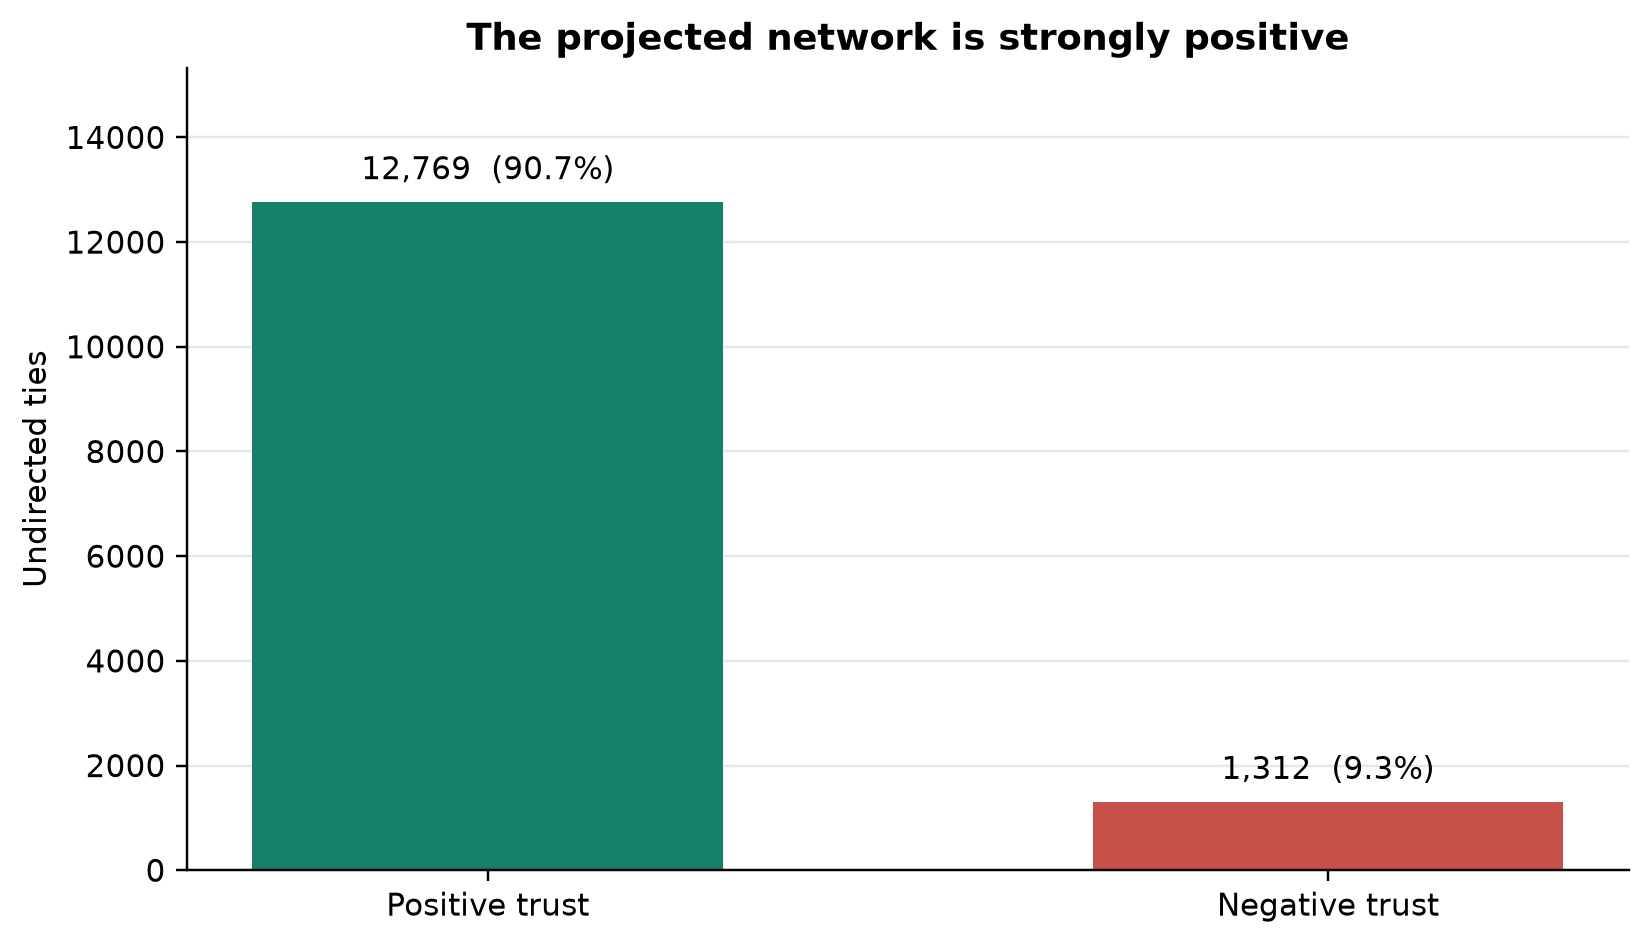

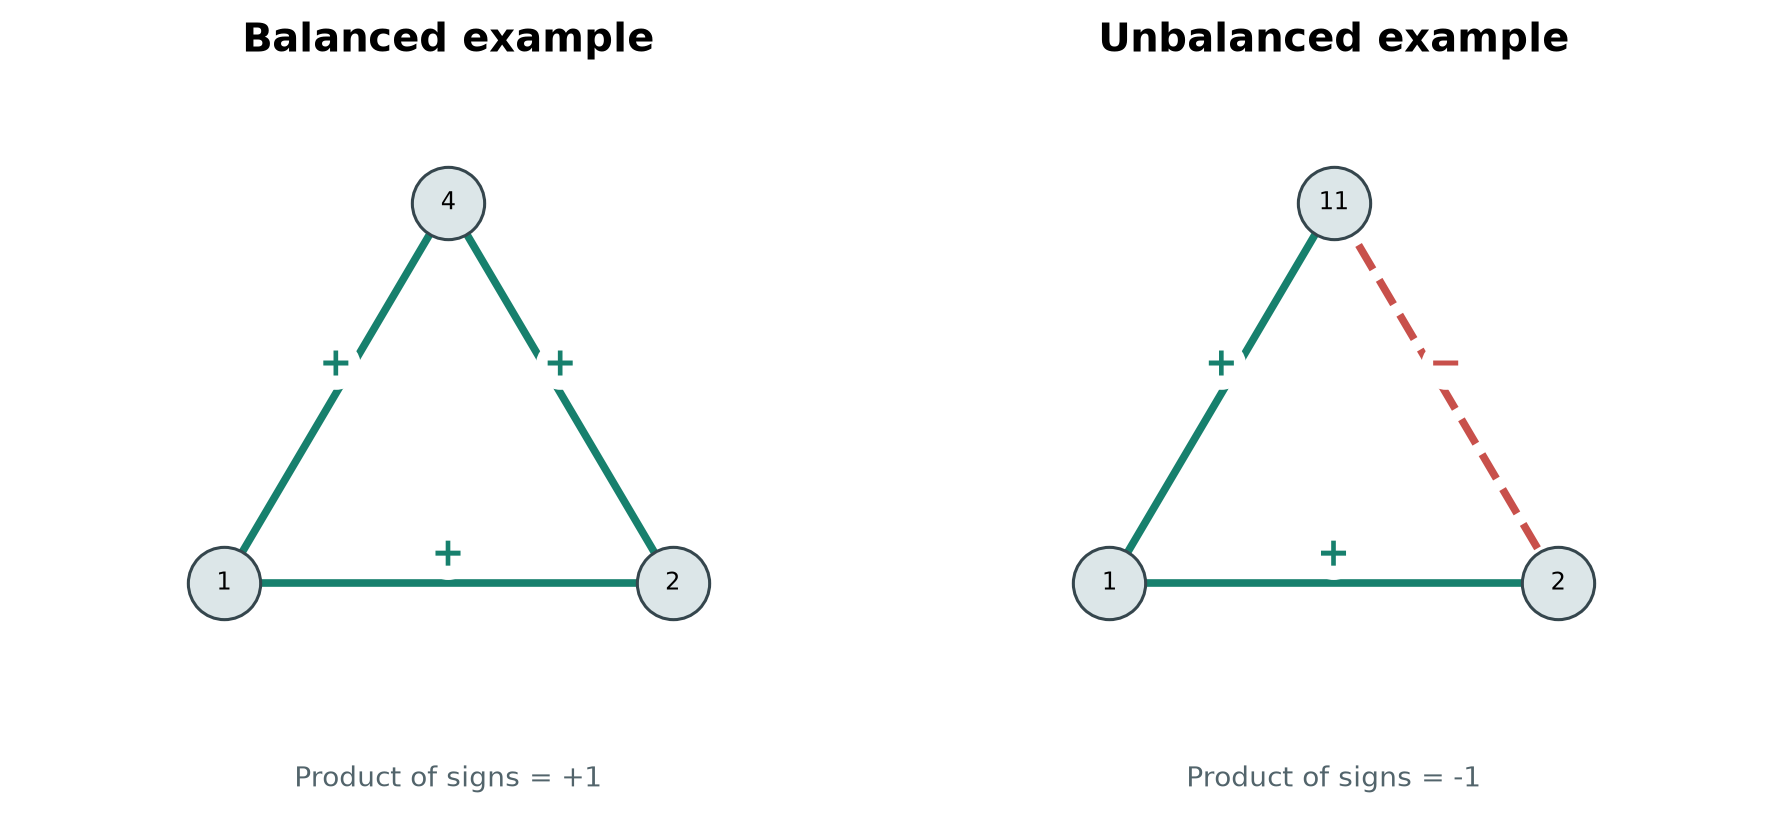

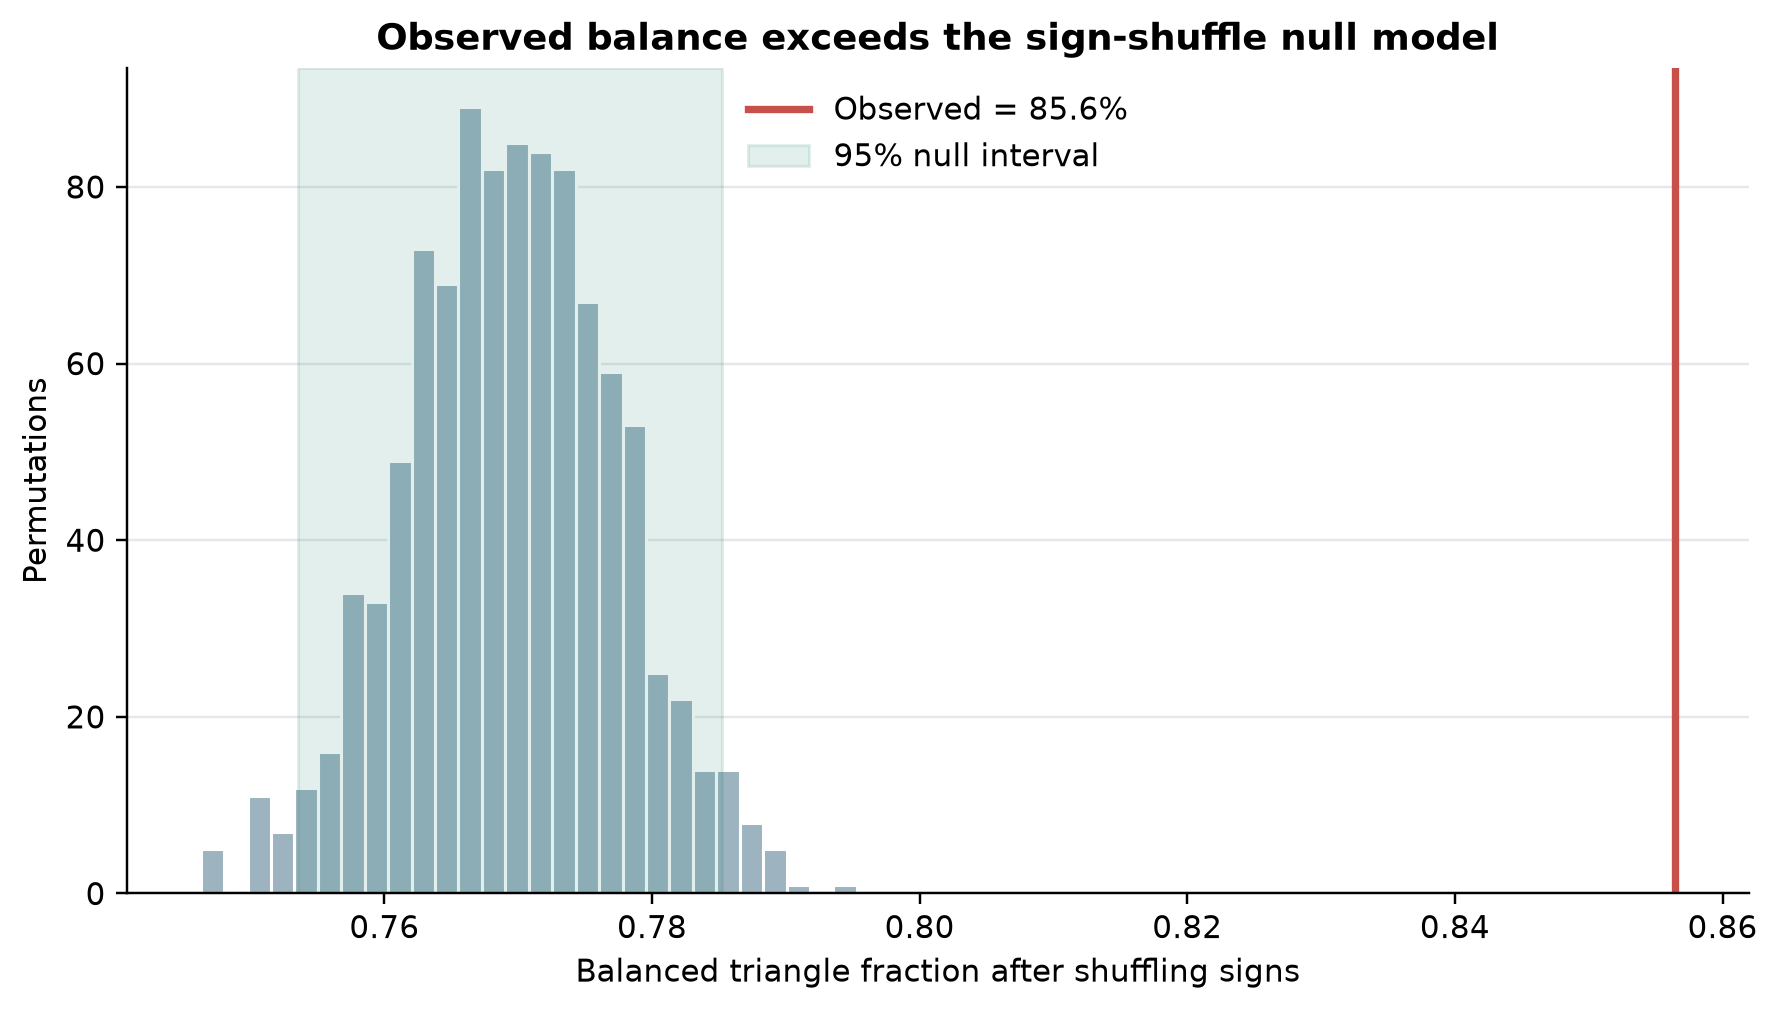

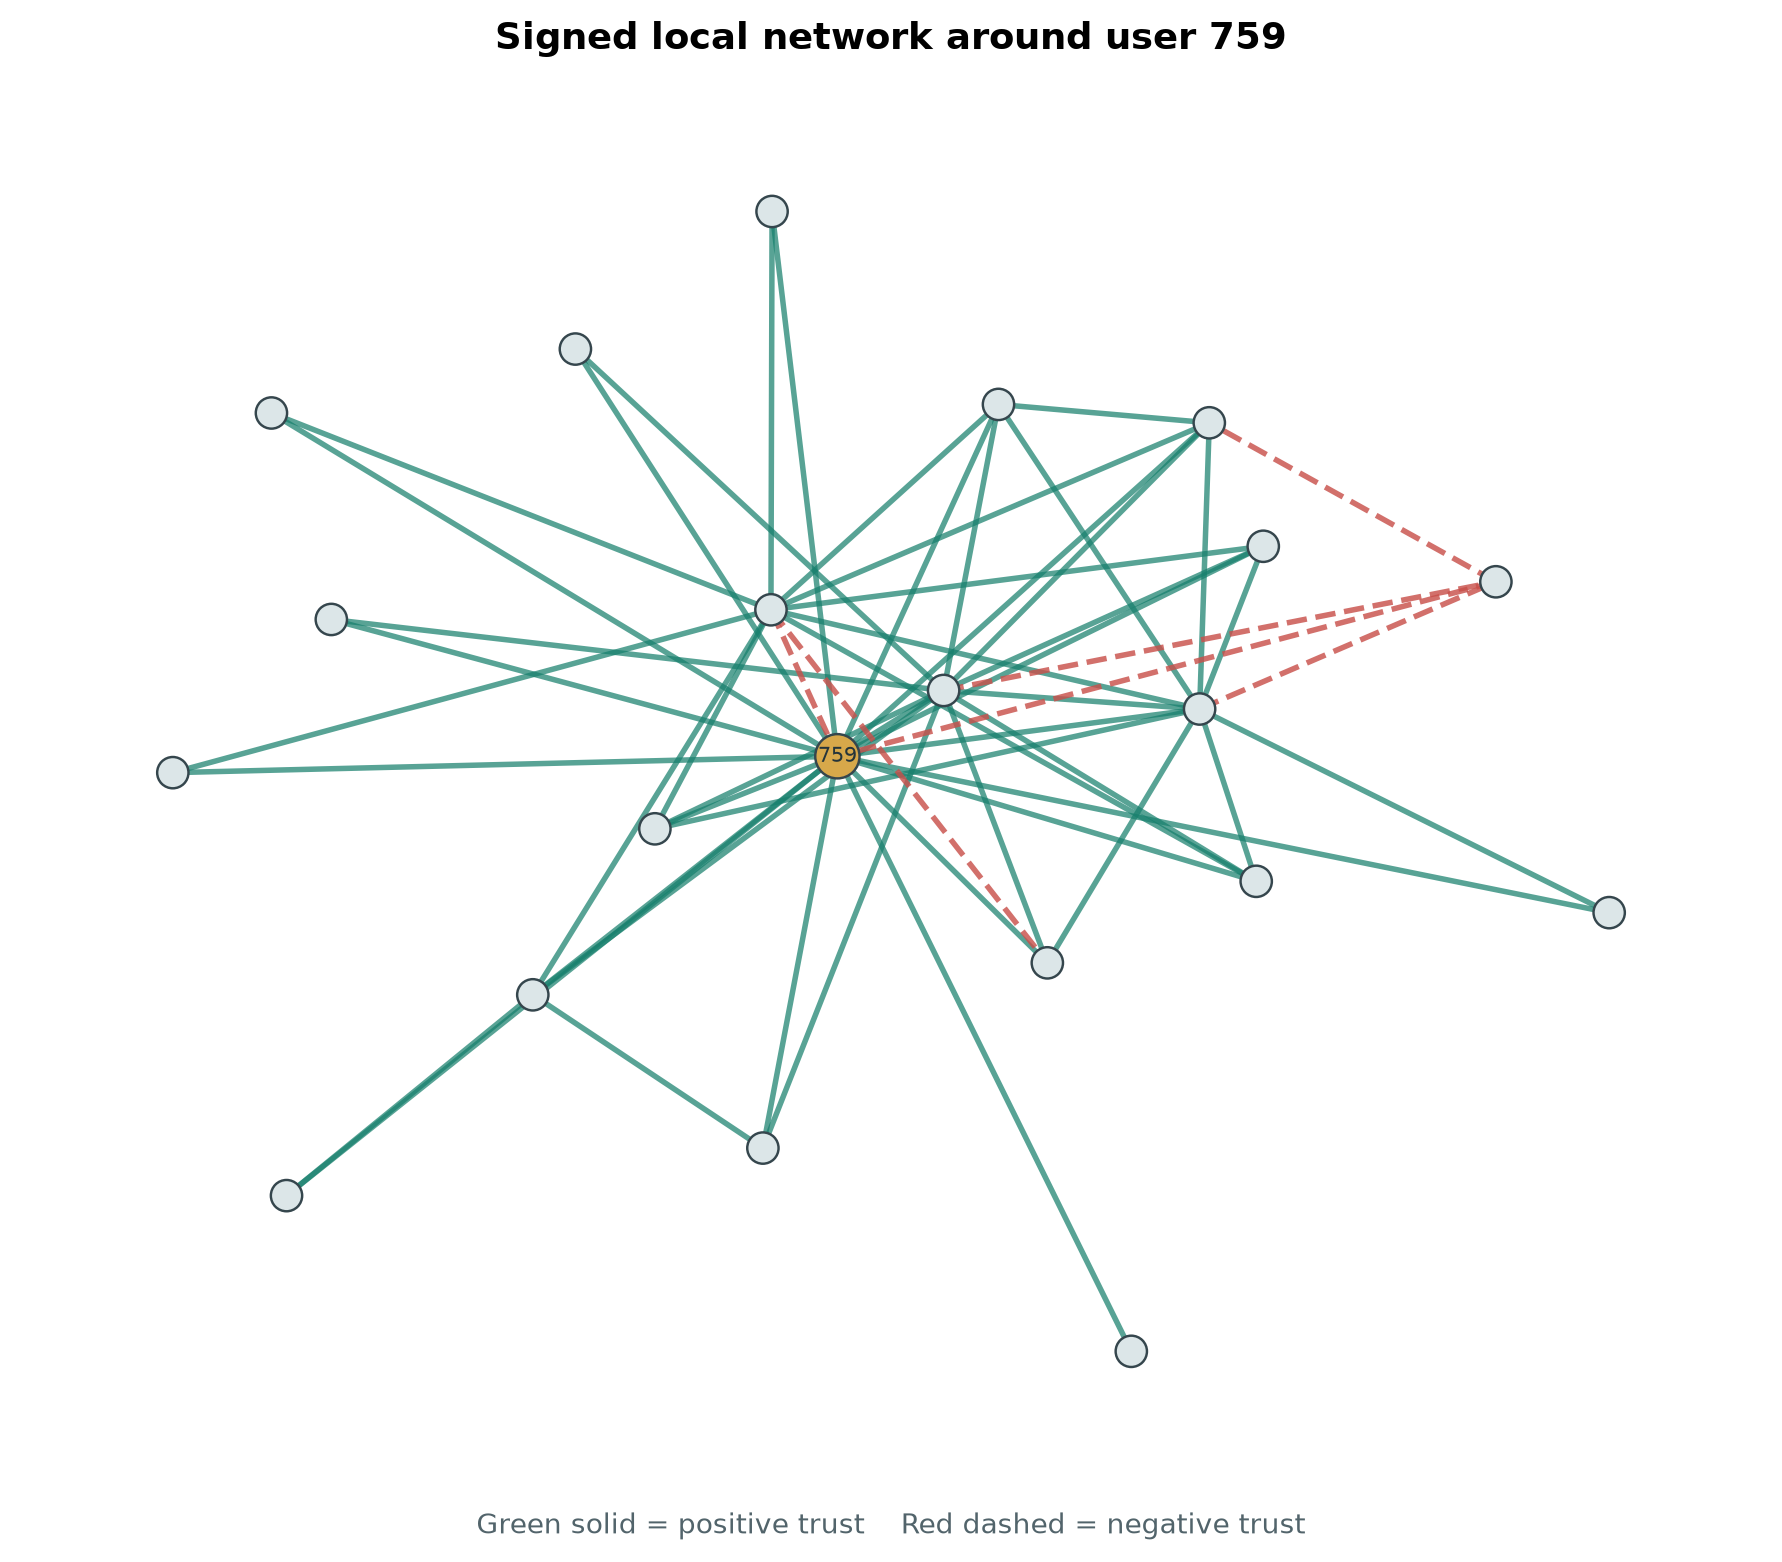

In [4]:
display(Image(filename=str(ROOT / "visualizations" / "edge_sign_distribution.png")))
display(Image(filename=str(ROOT / "visualizations" / "structural_balance_triads.png")))
display(Image(filename=str(ROOT / "visualizations" / "balance_null_model.png")))
display(Image(filename=str(ROOT / "visualizations" / "signed_ego_network.png")))

## 4. Interpretation

The observed balanced-triad share is about 8.7 percentage points above the sign-shuffle mean. The topology and the overall positive/negative tie counts alone do not explain the observed fraction under this null. Signs are arranged in ways that produce more balanced closed triads.

The undirected graph is sparse and dominated by positive ties. These features matter: with about 90.7% positive ties, many triangles will be balanced even under random assignment. That is why the comparison uses a null model rather than interpreting 85.6% in isolation.

## 5. Limitations

- Averaging both directions creates one undirected tie and can hide disagreement between users.
- Exact zero means are excluded, so results depend on the projection rule.
- The sign-shuffle null preserves total sign counts but not node-level sign tendencies, edge weights, or time order.
- Triads are dependent because they share edges; the permutation test handles the fixed graph dependence under the chosen null but does not make triangles independent observations.
- User IDs are anonymous dataset identifiers. The analysis cannot infer real-world identities, motives, or current platform behavior.
- The data are historical, spanning 2010-2015 based on the supplied timestamps.

## 6. Reproducibility and references

Run `python src/analyze.py` from the project root, or execute this notebook. The analysis uses seed 2026 and 1,000 permutations. See `README.md` for the environment setup and `data/README.md` for the original data source.

Kumar, S., Spezzano, F., Subrahmanian, V. S., & Faloutsos, C. (2016). “Edge Weight Prediction in Weighted Signed Networks.” IEEE International Conference on Data Mining. Dataset: [Stanford SNAP Bitcoin Alpha page](https://snap.stanford.edu/data/soc-sign-bitcoinalpha.html).